# Task 1: Aruco Marker Detection


In this notebook, we will look into how we can load an image, preprocess it and then detect Aruco markers in that image.


## Setup


If you haven't installed OpenCV yet, you can just run the cell below to install it.


In [110]:
# install opencv
#!pip install opencv-python
#!pip install opencv-contrib-python


## Imports


In [111]:
# imports
# 

import cv2
from matplotlib import pyplot as plt
import numpy as np

import yaml
import io


## Load and Preprocess Image


We start by loading one of the images from the recorded robot trajectory and displaying it.


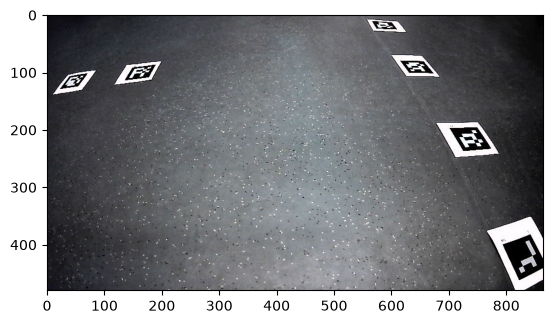

In [112]:
# load image
img = cv2.imread(r"2024-09-12_17-29-34/img_674.jpg")
# show image (convert BGR -> RGB for correct colours in matplotlib)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))


As you can see, the image is somewhat distorted. There is, for example, a very noticeable fisheye effect on the image. Using the image like this would negatively impact our detection and later measurement, so we first want to get rid of this distortion. This is what *camera calibration* is needed for.  
Let's first load the intrinsic camera parameters from the *camera_intrinsics.yml* file:


In [113]:
# load camera parameters
with open("camera_intrinsics.yml", 'r') as stream:
    camera_intrinsics = yaml.safe_load(stream)
camera_matrix = np.array(camera_intrinsics["camera_matrix"]["data"]).reshape((3,3))
distortion_coefficients = np.array(camera_intrinsics["distortion_coefficients"]["data"])


Now we can use the camera parameters to undistort the image. OpenCV already provides a function for this (helpfully called *undistort*).  
**Task:** Use OpenCV's *undistort* function to undistort the image and assign the result to *img_undistorted*.


In [114]:
### Your code here ###
# use the camera parameters to undistort the image
h, w = img.shape[:2]

new_K, roi = cv2.getOptimalNewCameraMatrix(
    camera_matrix, distortion_coefficients, (w, h), alpha=0
)

img_undistorted = cv2.undistort(img,camera_matrix,distortion_coefficients,None, new_K)

###


When we now display the image again, we can see that the distortion that was very noticeable in the image before applying the *undistort* function, is now gone.


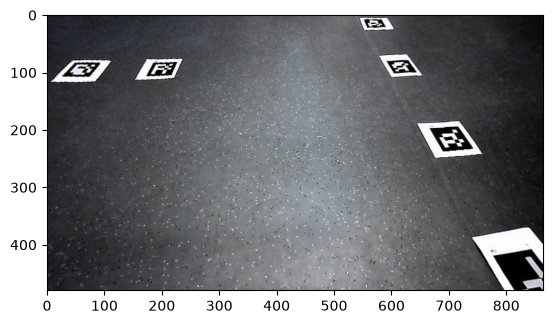

In [115]:
# show undistorted image
# plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.imshow(cv2.cvtColor(img_undistorted, cv2.COLOR_BGR2RGB))


## Detect Aruco Markers


Now that we have undistorted the image, we can start detecting the Aruco markers. This is a fundamental task for the project, since we will use markers as the main features that define our world! OpenCV already provides us with a function that can detect the markers in the image. After doing that we can draw them onto the image to see, what the algorithm has detected.


**Task:** Detect the Aruco markers in the image using the *cv2.aruco.ArucoDetector* function with the *cv2.aruco.DICT_ARUCO_ORIGINAL* marker dict. Store the detected corners and ids in the variables *corners* and *ids*.


In [116]:
### Your code here ###
# setup the aruco detector with the requested dictionary
aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_ARUCO_ORIGINAL)

# 2. Set detector parameters (defaults)
aruco_params = cv2.aruco.DetectorParameters()

# detect markers in the undistorted image
detector = cv2.aruco.ArucoDetector(aruco_dict, aruco_params)

# 4. Detect markers in a grayscale image
#gray = cv2.cvtColor(img_undistorted, cv2.COLOR_BGR2GRAY)
gray = cv2.cvtColor(img_undistorted, cv2.COLOR_BGR2GRAY)
corners, ids, rejected = detector.detectMarkers(gray)
###

print("Detected marker ids:", ids.ravel() if ids is not None else None)


Detected marker ids: [620 665 743]


**Task:** Draw the outlines of the detected markers onto the image using the *cv2.aruco.drawDetectedMarkers* function and store the result in *img_with_markers*.


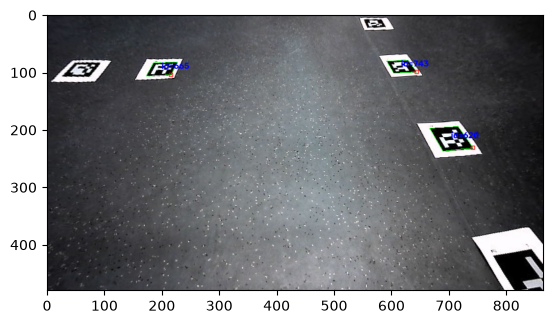

In [117]:
# image = img
### Your code here ###
# draw the detected markers onto the image
img_with_markers = cv2.aruco.drawDetectedMarkers(img_undistorted, corners, ids=ids)
###

# display the annotated image (convert BGR -> RGB for correct colours in matplotlib)
plt.figure()
plt.imshow(cv2.cvtColor(img_with_markers, cv2.COLOR_BGR2RGB))
plt.show()
